In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project data directory
data_dir = Path("../data/processed")

# Load macroeconomic data (Days 1–3)
macro = pd.read_csv(
    data_dir / "us_macro_2008_2025.csv",
    parse_dates=["observation_date"]
)

# Load financial returns (Days 4–5)
etf_returns = pd.read_csv(
    data_dir / "us_etf_monthly_returns_2008_2025.csv",
    parse_dates=["observation_date"]
)

# Merge by calendar month
master = pd.merge(
    macro,
    etf_returns,
    on="observation_date",
    how="inner",
    validate="one_to_one"
)

master = master.sort_values(
    "observation_date"
).reset_index(drop=True)

# Validate date alignment
assert master.shape[0] == 216
assert master["observation_date"].is_unique

print("Master dataset shape:", master.shape)

print("\nDate range:")
print(master["observation_date"].min())
print(master["observation_date"].max())

print("\nMissing values:")
print(master.isna().sum())

print("\nFirst 5 observations:")
display(master.head())


Master dataset shape: (216, 11)

Date range:
2008-01-01 00:00:00
2025-12-01 00:00:00

Missing values:
observation_date          0
CPIAUCSL                  1
inflation_yoy             1
FEDFUNDS                  0
fed_change_pp             0
UNRATE                    1
unemployment_change_pp    2
inflation_change_pp       3
SPY                       0
IEF                       0
GLD                       0
dtype: int64

First 5 observations:


,observation_date,CPIAUCSL,inflation_yoy,FEDFUNDS,fed_change_pp,UNRATE,unemployment_change_pp,inflation_change_pp,SPY,IEF,GLD
0,2008-01-01,212.174,4.294696,3.94,-0.30,5.0,0.0,NaN,-6.046152,3.355933,10.841623
1,2008-02-01,212.687,4.142959,2.98,-0.96,4.9,-0.1,-0.151736,-2.584258,1.239337,5.229758
2,2008-03-01,213.448,3.974904,2.61,-0.37,5.1,0.2,-0.168056,-0.894229,1.337266,-5.999165
3,2008-04-01,213.942,3.903761,2.28,-0.33,5.0,-0.1,-0.071143,4.766256,-2.417414,-4.158834
4,2008-05-01,215.208,4.088414,1.98,-0.30,5.4,0.4,0.184653,1.511625,-1.777456,0.923249


In [2]:

# Classify monthly inflation into three regimes

regime_labels = [
    "Low Inflation",
    "Moderate Inflation",
    "High Inflation"
]

master["inflation_regime"] = pd.cut(
    master["inflation_yoy"],
    bins=[-np.inf, 2, 4, np.inf],
    labels=regime_labels,
    right=False
)

# Count observations in each regime
regime_counts = (
    master["inflation_regime"]
    .value_counts(sort=False)
)

regime_summary = pd.DataFrame({
    "months": regime_counts,
    "share_pct": regime_counts / len(master) * 100
})

print("Inflation Regime Distribution:")
display(regime_summary.round(2))

print("\nUnclassified months:")
print(master["inflation_regime"].isna().sum())

print("\nInflation range within each regime:")
display(
    master.groupby(
        "inflation_regime",
        observed=True
    )["inflation_yoy"].agg(
        ["count", "min", "max", "mean"]
    ).round(2)
)

# Validate regime assignments
assert regime_counts.sum() == 215
assert master["inflation_regime"].isna().sum() == 1


Inflation Regime Distribution:


,months,share_pct
inflation_regime,,
Low Inflation,96,44.44
Moderate Inflation,86,39.81
High Inflation,33,15.28



Unclassified months:
1

Inflation range within each regime:


,count,min,max,mean
inflation_regime,,,,
Low Inflation,96,-1.96,1.97,1.00
Moderate Inflation,86,2.00,3.97,2.73
High Inflation,33,4.09,8.98,6.24


In [3]:

# Compare ETF returns across inflation regimes

assets = ["SPY", "IEF", "GLD"]

regime_groups = master.groupby(
    "inflation_regime",
    observed=True
)

# Mean monthly returns (%) by regime
regime_mean_returns = regime_groups[assets].mean()

# Median monthly returns (%) by regime
regime_median_returns = regime_groups[assets].median()

# Number of observations per regime
regime_n = regime_groups.size()

print("Mean Monthly Returns (%) by Inflation Regime:")
display(regime_mean_returns.round(3))

print("\nMedian Monthly Returns (%) by Inflation Regime:")
display(regime_median_returns.round(3))

print("\nNumber of Months:")
display(regime_n)

# Validate the analysis sample
assert regime_n.sum() == 215
assert not regime_mean_returns.isna().any().any()


Mean Monthly Returns (%) by Inflation Regime:


,SPY,IEF,GLD
inflation_regime,,,
Low Inflation,1.476,0.327,0.693
Moderate Inflation,0.916,0.339,0.965
High Inflation,-0.375,-0.117,0.914



Median Monthly Returns (%) by Inflation Regime:


,SPY,IEF,GLD
inflation_regime,,,
Low Inflation,1.792,0.061,0.217
Moderate Inflation,1.822,0.276,0.431
High Inflation,0.462,-0.140,0.862



Number of Months:


inflation_regime
Low Inflation         96
Moderate Inflation    86
High Inflation        33
dtype: int64

In [4]:

# Risk analysis across inflation regimes

# Monthly standard deviation of ETF returns
regime_volatility = regime_groups[assets].std(ddof=1)

# Percentage of months with negative returns
regime_negative_months = regime_groups[assets].agg(
    lambda x: (x < 0).mean() * 100
)

print("Monthly Volatility (%) by Inflation Regime:")
display(regime_volatility.round(3))

print("\nNegative Return Months (%) by Inflation Regime:")
display(regime_negative_months.round(2))

print("\nSample Sizes:")
display(regime_n)


Monthly Volatility (%) by Inflation Regime:


,SPY,IEF,GLD
inflation_regime,,,
Low Inflation,4.481,1.947,5.075
Moderate Inflation,4.185,1.808,4.860
High Inflation,5.359,2.331,4.647



Negative Return Months (%) by Inflation Regime:


,SPY,IEF,GLD
inflation_regime,,,
Low Inflation,30.21,47.92,47.92
Moderate Inflation,31.40,44.19,46.51
High Inflation,45.45,51.52,48.48



Sample Sizes:


inflation_regime
Low Inflation         96
Moderate Inflation    86
High Inflation        33
dtype: int64

In [5]:

# Asset return correlations across inflation regimes

regime_correlation_results = []

for regime in regime_labels:

    # Select months belonging to this inflation regime
    regime_data = master.loc[
        master["inflation_regime"] == regime,
        assets
    ]

    # Calculate Pearson correlations of ETF returns
    corr = regime_data.corr(method="pearson")

    regime_correlation_results.append({
        "Inflation Regime": regime,
        "Observations": len(regime_data),
        "SPY-IEF": corr.loc["SPY", "IEF"],
        "SPY-GLD": corr.loc["SPY", "GLD"],
        "IEF-GLD": corr.loc["IEF", "GLD"]
    })

regime_correlations = pd.DataFrame(
    regime_correlation_results
).set_index("Inflation Regime")

print("ETF Correlations by Inflation Regime:")
display(regime_correlations.round(3))

# Validate regime sample sizes
assert (
    regime_correlations["Observations"].tolist()
    == [96, 86, 33]
)

assert not regime_correlations.isna().any().any()

print("\nREGIME CORRELATION VALIDATION: PASSED")


ETF Correlations by Inflation Regime:


,Observations,SPY-IEF,SPY-GLD,IEF-GLD
Inflation Regime,,,,
Low Inflation,96,-0.262,-0.004,0.405
Moderate Inflation,86,-0.135,0.188,0.249
High Inflation,33,0.421,0.045,0.467



REGIME CORRELATION VALIDATION: PASSED


In [6]:

# Check the historical distribution of high-inflation months

high_inflation = master.loc[
    master["inflation_regime"] == "High Inflation"
].copy()

# Identify the calendar year of each observation
high_inflation["year"] = (
    high_inflation["observation_date"].dt.year
)

# Count high-inflation months per year
high_inflation_years = (
    high_inflation.groupby("year")
    .size()
    .to_frame("months")
)

# Percentage of all high-inflation observations
high_inflation_years["share_pct"] = (
    high_inflation_years["months"]
    / len(high_inflation) * 100
)

print("High Inflation Months by Year:")
display(high_inflation_years.round(2))

print("\nTotal high-inflation months:", len(high_inflation))

print(
    "High-inflation months before 2020:",
    (high_inflation["year"] < 2020).sum()
)

print(
    "High-inflation months from 2020 onward:",
    (high_inflation["year"] >= 2020).sum()
)


High Inflation Months by Year:


,months,share_pct
year,,
2008,7,21.21
2021,9,27.27
2022,12,36.36
2023,5,15.15



Total high-inflation months: 33
High-inflation months before 2020: 7
High-inflation months from 2020 onward: 26


In [7]:

# Robustness Check: Leave-One-Year-Out
# Stock-Bond Correlation in High Inflation Months

high_data = master.loc[
    master["inflation_regime"] == "High Inflation",
    ["observation_date", "SPY", "IEF"]
].copy()

high_data["year"] = (
    high_data["observation_date"].dt.year
)

# Full high-inflation sample
full_corr = high_data["SPY"].corr(
    high_data["IEF"]
)

results = [{
    "excluded_year": "None",
    "observations": len(high_data),
    "spy_ief_corr": full_corr
}]

# Remove one calendar year at a time
for year in sorted(high_data["year"].unique()):

    subset = high_data.loc[
        high_data["year"] != year
    ]

    corr = subset["SPY"].corr(
        subset["IEF"]
    )

    results.append({
        "excluded_year": str(year),
        "observations": len(subset),
        "spy_ief_corr": corr
    })

robustness_high_inflation = pd.DataFrame(results)

print("High Inflation — Leave-One-Year-Out Analysis")
display(robustness_high_inflation.round(3))


High Inflation — Leave-One-Year-Out Analysis


,excluded_year,observations,spy_ief_corr
0,None,33,0.421
1,2008,26,0.633
2,2021,24,0.429
3,2022,21,0.137
4,2023,28,0.356


In [8]:

# Classify monetary policy regimes

rate_change = master["fed_change_pp"]

master["rate_regime"] = np.select(
    [
        rate_change > 0.10,
        rate_change < -0.10
    ],
    [
        "Rising Rates",
        "Falling Rates"
    ],
    default="Stable Rates"
)

# Count monthly observations
rate_counts = master["rate_regime"].value_counts()

print("Monetary Policy Regime Distribution:")
display(rate_counts)

# Compare inflation and monetary policy regimes
regime_crosstab = pd.crosstab(
    master["inflation_regime"],
    master["rate_regime"]
)

print("\nInflation vs Monetary Policy Regimes:")
display(regime_crosstab)

# Validate classification
assert rate_counts.sum() == 216
assert master["rate_regime"].notna().all()


Monetary Policy Regime Distribution:


rate_regime
Stable Rates     165
Rising Rates      28
Falling Rates     23
Name: count, dtype: int64


Inflation vs Monetary Policy Regimes:


rate_regime,Falling Rates,Rising Rates,Stable Rates
inflation_regime,,,
Low Inflation,6,4,86
Moderate Inflation,12,10,64
High Inflation,4,14,15


In [9]:

# ETF returns across monetary policy regimes

rate_order = [
    "Falling Rates",
    "Stable Rates",
    "Rising Rates"
]

rate_groups = master.groupby("rate_regime")

# Mean monthly returns (%)
rate_mean_returns = (
    rate_groups[assets]
    .mean()
    .reindex(rate_order)
)

# Median monthly returns (%)
rate_median_returns = (
    rate_groups[assets]
    .median()
    .reindex(rate_order)
)

# Number of observations
rate_n = (
    rate_groups
    .size()
    .reindex(rate_order)
)

print("Mean Monthly Returns (%) by Rate Regime:")
display(rate_mean_returns.round(3))

print("\nMedian Monthly Returns (%) by Rate Regime:")
display(rate_median_returns.round(3))

print("\nNumber of Months:")
display(rate_n)

# Validate results
assert rate_n.sum() == 216
assert not rate_mean_returns.isna().any().any()


Mean Monthly Returns (%) by Rate Regime:


,SPY,IEF,GLD
rate_regime,,,
Falling Rates,-0.745,0.872,2.779
Stable Rates,1.319,0.326,0.696
Rising Rates,0.354,-0.590,0.161



Median Monthly Returns (%) by Rate Regime:


,SPY,IEF,GLD
rate_regime,,,
Falling Rates,0.195,0.651,4.112
Stable Rates,1.921,0.237,0.356
Rising Rates,0.606,-0.378,-0.703



Number of Months:


rate_regime
Falling Rates     23
Stable Rates     165
Rising Rates      28
dtype: int64

In [10]:

# Joint Inflation and Monetary Policy Regime Analysis

joint_regime_results = (
    master.groupby(
        ["inflation_regime", "rate_regime"],
        observed=True
    )
    .agg(
        observations=("SPY", "size"),
        SPY_mean=("SPY", "mean"),
        IEF_mean=("IEF", "mean"),
        GLD_mean=("GLD", "mean")
    )
    .reset_index()
)

# Flag groups with very small samples
joint_regime_results["small_sample"] = (
    joint_regime_results["observations"] < 10
)

print("Joint Regime Asset Returns (%):")
display(joint_regime_results.round(3))

print("\nTotal classified observations:")
print(joint_regime_results["observations"].sum())

print("\nGroups with fewer than 10 observations:")
print(joint_regime_results["small_sample"].sum())

assert joint_regime_results["observations"].sum() == 215


Joint Regime Asset Returns (%):


,inflation_regime,rate_regime,observations,SPY_mean,IEF_mean,GLD_mean,small_sample
0,Low Inflation,Falling Rates,6,-0.872,3.508,6.303,True
1,Low Inflation,Rising Rates,4,2.243,0.016,0.648,True
2,Low Inflation,Stable Rates,86,1.604,0.120,0.304,False
3,Moderate Inflation,Falling Rates,12,0.188,-0.365,0.120,False
4,Moderate Inflation,Rising Rates,10,0.434,-0.279,0.642,False
5,Moderate Inflation,Stable Rates,64,1.127,0.567,1.173,False
6,High Inflation,Falling Rates,4,-4.134,0.669,5.277,True
7,High Inflation,Rising Rates,14,-0.243,-0.986,-0.321,False
8,High Inflation,Stable Rates,15,0.504,0.485,0.904,False



Total classified observations:
215

Groups with fewer than 10 observations:
3


In [11]:

# Examine the timing of monetary policy regimes
# within high-inflation months

high_inflation_sample = master.loc[
    master["inflation_regime"] == "High Inflation",
    ["observation_date", "rate_regime", "SPY", "IEF", "GLD"]
].copy()

high_inflation_sample["year"] = (
    high_inflation_sample["observation_date"].dt.year
)

# Count months by year and rate regime
high_rate_distribution = pd.crosstab(
    high_inflation_sample["year"],
    high_inflation_sample["rate_regime"]
)

high_rate_distribution = high_rate_distribution.reindex(
    columns=[
        "Falling Rates",
        "Stable Rates",
        "Rising Rates"
    ],
    fill_value=0
)

print("High Inflation: Monetary Policy Regimes by Year")
display(high_rate_distribution)

print("\nTotal observations by rate regime:")
display(high_rate_distribution.sum())

assert high_rate_distribution.to_numpy().sum() == 33


High Inflation: Monetary Policy Regimes by Year


rate_regime,Falling Rates,Stable Rates,Rising Rates
year,,,
2008,4,3,0
2021,0,9,0
2022,0,2,10
2023,0,1,4



Total observations by rate regime:


rate_regime
Falling Rates     4
Stable Rates     15
Rising Rates     14
dtype: int64

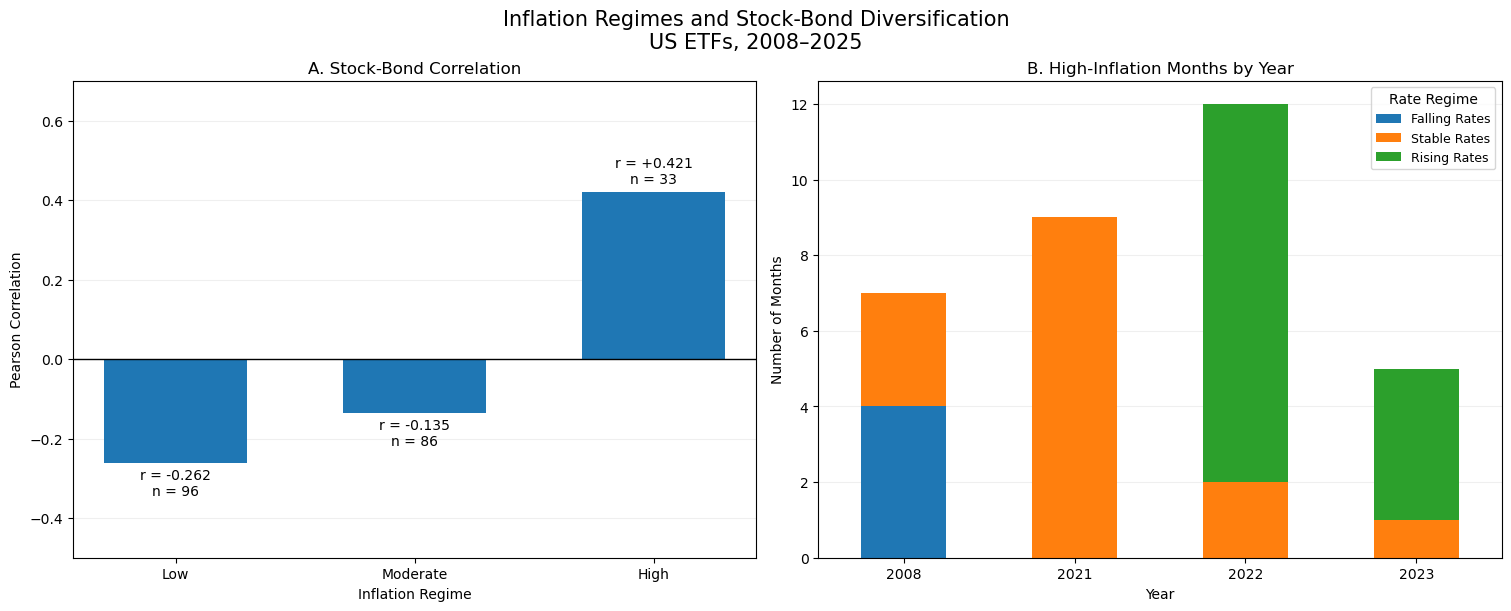

In [12]:

# Inflation Regimes and Stock-Bond Diversification

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    layout="constrained"
)

# Panel A: Stock-bond correlations by inflation regime

corr_values = regime_correlations["SPY-IEF"]
sample_sizes = regime_correlations["Observations"]

x = np.arange(len(corr_values))

bars = axes[0].bar(
    x,
    corr_values,
    width=0.6
)

axes[0].bar_label(
    bars,
    labels=[
        f"r = {r:+.3f}\nn = {int(n)}"
        for r, n in zip(corr_values, sample_sizes)
    ],
    padding=4,
    fontsize=10
)

axes[0].set_xticks(x)
axes[0].set_xticklabels([
    "Low",
    "Moderate",
    "High"
])

axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_ylim(-0.5, 0.7)
axes[0].set_ylabel("Pearson Correlation")
axes[0].set_xlabel("Inflation Regime")
axes[0].set_title("A. Stock-Bond Correlation")
axes[0].grid(axis="y", alpha=0.2)
axes[0].set_axisbelow(True)

# Panel B: High-inflation months by year and rate regime

rate_columns = [
    "Falling Rates",
    "Stable Rates",
    "Rising Rates"
]

high_rate_distribution[rate_columns].plot(
    kind="bar",
    stacked=True,
    ax=axes[1],
    rot=0
)

axes[1].set_title(
    "B. High-Inflation Months by Year"
)
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Number of Months")
axes[1].legend(
    title="Rate Regime",
    fontsize=9
)

axes[1].grid(axis="y", alpha=0.2)
axes[1].set_axisbelow(True)

fig.suptitle(
    "Inflation Regimes and Stock-Bond Diversification"
    "\nUS ETFs, 2008–2025",
    fontsize=15
)

# Save the figure
output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_dir / "inflation_stock_bond_diversification.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [13]:

# Robustness Check: Inflation Threshold Sensitivity

inflation_thresholds = [3.0, 4.0, 5.0, 6.0]

threshold_results = []

for threshold in inflation_thresholds:

    subset = master.loc[
        master["inflation_yoy"] >= threshold,
        ["observation_date", "SPY", "IEF"]
    ].dropna()

    correlation = subset["SPY"].corr(subset["IEF"])

    threshold_results.append({
        "inflation_threshold_pct": threshold,
        "observations": len(subset),
        "spy_ief_correlation": correlation,
        "distinct_years": subset[
            "observation_date"
        ].dt.year.nunique()
    })

threshold_sensitivity = pd.DataFrame(
    threshold_results
)

print("Inflation Threshold Sensitivity Analysis:")
display(threshold_sensitivity.round(3))


Inflation Threshold Sensitivity Analysis:


,inflation_threshold_pct,observations,spy_ief_correlation,distinct_years
0,3.0,59,0.279,8
1,4.0,33,0.421,4
2,5.0,23,0.617,4
3,6.0,16,0.617,3


In [14]:

from pathlib import Path

processed_dir = Path("../data/processed")
tables_dir = Path("../reports/tables")

processed_dir.mkdir(parents=True, exist_ok=True)
tables_dir.mkdir(parents=True, exist_ok=True)

# Final validation
assert len(master) == 216
assert master["observation_date"].is_unique
assert master["inflation_regime"].notna().sum() == 215
assert master[["SPY", "IEF", "GLD"]].notna().all().all()

# Save the master analytical dataset
master.to_csv(
    processed_dir / "us_macro_etf_master_2008_2025.csv",
    index=False
)

# Save inflation regime returns
regime_mean_returns.to_csv(
    tables_dir / "inflation_regime_mean_returns.csv",
    index_label="inflation_regime"
)

# Save asset correlations by inflation regime
regime_correlations.to_csv(
    tables_dir / "inflation_regime_asset_correlations.csv",
    index_label="inflation_regime"
)

# Save joint inflation and monetary policy analysis
joint_regime_results.to_csv(
    tables_dir / "joint_macro_regime_returns.csv",
    index=False
)

# Save inflation threshold robustness results
threshold_sensitivity.to_csv(
    tables_dir / "inflation_threshold_sensitivity.csv",
    index=False
)

print("DAY 6 RESULTS SAVED SUCCESSFULLY")

print("\nMaster dataset shape:", master.shape)
print("Classified months:",
      master["inflation_regime"].notna().sum())


DAY 6 RESULTS SAVED SUCCESSFULLY

Master dataset shape: (216, 13)
Classified months: 215



## Key Findings and Economic Interpretation

### 1. Macroeconomic Regime Classification

This analysis combines monthly US macroeconomic indicators with ETF returns for SPY, IEF, and GLD over 2008–2025.

Inflation regimes were defined using annual CPI inflation:

- Low Inflation: below 2%
- Moderate Inflation: 2% to below 4%
- High Inflation: 4% or above

The resulting groups contained 96, 86, and 33 months, respectively. One month could not be classified because inflation data were missing.

Monetary policy regimes were also classified using monthly changes in the effective Federal Funds Rate.

### 2. Asset Performance Across Inflation Regimes

Mean monthly returns in high-inflation months were:

- SPY: -0.375%
- IEF: -0.117%
- GLD: +0.914%

SPY also exhibited greater monthly volatility during high-inflation months (5.359%) than during low-inflation months (4.481%).

These findings suggest that historical asset performance differed across inflation environments.

However, median returns and the frequency of negative months reveal that average returns do not fully describe the underlying return distributions.

### 3. Stock-Bond Diversification

The SPY–IEF monthly return correlations were:

- Low Inflation: -0.262
- Moderate Inflation: -0.135
- High Inflation: +0.421

The positive stock-bond correlation during high-inflation months suggests that historical diversification benefits may have been weaker in these environments.

However, correlation alone does not quantify portfolio risk reduction.

### 4. Robustness and Historical Concentration

Of the 33 high-inflation months, 26 occurred during 2021–2023 and seven during 2008.

Leave-one-year-out analysis showed that the high-inflation SPY–IEF correlation remained positive, but its magnitude varied substantially.

For example, excluding 2022 reduced the correlation from +0.421 to +0.137.

Sensitivity analysis using inflation thresholds of 3%, 4%, 5%, and 6% also produced positive stock-bond correlations, ranging from +0.279 to +0.617.

These findings support the descriptive consistency of the positive correlation across selected thresholds, but not its generalizability across independent inflationary episodes.

### 5. Monetary Policy and Asset Returns

During rising-rate months, mean monthly returns were:

- SPY: +0.354%
- IEF: -0.590%
- GLD: +0.161%

Within the joint High Inflation and Rising Rates group, all three ETFs exhibited negative mean monthly returns.

However, this joint group contained only 14 observations, all from 2022–2023.

Therefore, the independent effects of inflation and monetary policy cannot be established from these comparisons.

## Methodological Limitations

- Results are descriptive and do not establish causality.
- Inflation regimes are based on CPI, while the Federal Reserve's 2% inflation target refers to PCE inflation.
- Regime thresholds are analytical choices rather than universally accepted definitions.
- The interest-rate classification uses changes in the effective Federal Funds Rate, not individual policy decisions.
- High-inflation observations are concentrated in a small number of historical episodes.
- Monthly observations can exhibit serial dependence.
- Correlation differences have not yet been subjected to formal statistical significance testing.
- Inflation and interest-rate conditions may be jointly related to other economic shocks.
- Same-month CPI and return comparisons use inflation information published after the relevant trading period. They are not directly implementable investment signals.
- ETF returns exclude investor-specific taxes and transaction costs.

## Main Research Conclusion

Historical stock-bond correlations and asset returns differed across inflation environments during 2008–2025.

The positive SPY–IEF correlation observed during high-inflation months is a potentially important finding for portfolio diversification.

However, its sensitivity to specific historical episodes and the concentration of observations require further statistical investigation.

## Next Steps

Day 7 will evaluate the statistical evidence more formally, including uncertainty, time-series dependence, and the relationship between macroeconomic conditions and asset returns.

Subsequent analysis will examine whether the observed differences translate into meaningful portfolio-level risk and diversification outcomes.
